# Módulo 3 - Punto 3.2: Procesamiento en video y curva temporal fisiológica

**Objetivo.** Automatizar la segmentación de la pupila en todo el video, validar el área/diámetro automático contra la anotación manual, obtener la curva temporal D(t) y A(t), extraer los parámetros fisiológicos del reflejo fotomotor (latencia, amplitud, velocidades) y documentar cómo se detectan y tratan los artefactos.

Toda la lógica está en `src/modulo3/dinamica.py` (y la máscara de cada frame en `src/modulo3/descriptores.py`); los parámetros, en la sección `modulo3` de `config.yaml`. No se usa aprendizaje automático: segmentación clásica (Módulo 2), morfología, estadística robusta (mediana, MAD) y filtrado de señales 1D. Las figuras y tablas se guardan en `results/modulo3/`.

## 0. Configuración del entorno e importaciones

In [25]:
# --- Imports de la librería estándar ---
import sys
from pathlib import Path

# --- Configurar la raíz del repositorio ---
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display

from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm
from src.modulo3 import descriptores as de
from src.modulo3 import dinamica as di      # funciones del punto 3.2

# --- Estilo de las figuras (el mismo del Módulo 4) ---
COLOR = {"crudo": "#a3a29b", "suave": "#0b0b0b", "rechazado": "#d0453a", "interp": "#2a78d6",
         "manual": "#ffffff", "auto": "#eda100", "watershed": "#2a78d6", "luz": "#f6e7b0"}
MOTIVO = {"forma": "Forma irregular", "salto_centroide": "Salto del centroide",
          "outlier": "Outlier (Hampel)", "sin_pupila": "Sin pupila (parpadeo)"}
COLOR_MOTIVO = {"forma": "#d0453a", "salto_centroide": "#8f4fd6", "outlier": "#eb6834", "sin_pupila": "#52514e"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "font.size": 10,
    "lines.linewidth": 2, "lines.markersize": 7,
})
pd.set_option("display.precision", 3)

def sombrear_luz(ax, est, t_fin):
    # Sombrea los intervalos con la luz encendida
    for t_on in est["encendido"]:
        apag = [t for t in est["apagado"] if t > t_on]
        ax.axvspan(t_on, apag[0] if apag else t_fin, color=COLOR["luz"], alpha=0.6, lw=0, zorder=0)

## 1. Procesamiento del video frame a frame

`di.procesar_registro` hace todo el recorrido. Para cada frame:

1. Recorta la ROI de `config.yaml` (la misma de todos los módulos).
2. Segmenta la pupila con `de.mascara_pupila`: pipeline del Módulo 2 (CLAHE + estimación del centro y radio + Watershed sobre el gradiente de Sobel) + **erosión k = 3, 2 iteraciones** (elegida en 2.2) + componente conexa más grande.
3. Calcula los descriptores de forma (`de.morfometria`, los mismos de 3.1): área, diámetro equivalente D = 2·√(A/π), perímetro, centroide, circularidad y excentricidad.
4. Guarda el **brillo medio del frame completo** (para detectar el estímulo) y, cada 10 frames, el radio del iris (para la escala en mm).

Después marca los artefactos y los interpola (sección 3), suaviza la curva, detecta el estímulo y extrae los parámetros (sección 5). Tarda unos 40 s para este video.

In [26]:
cfg = cargar_config(raiz / "config.yaml")
c3 = cfg["modulo3"]
carpeta_res = raiz / "results" / "modulo3"
carpeta_res.mkdir(parents=True, exist_ok=True)

ruta_video = raiz / cfg["entrada"]["video_path"]
info = di.info_video(ruta_video)
print(f"{ruta_video.name}: {info['ancho']}×{info['alto']} px, {info['fps']:.2f} fps, "
      f"{info['n_frames']} frames = {info['duracion_s']:.2f} s")

resultado = di.procesar_registro(ruta_video, cfg, verbose=False)
curva, est, par = resultado["curva"], resultado["estimulos"], resultado["parametros"]
print(f"Frames procesados: {len(curva)}  |  con pupila detectada: {int(curva.detectada.sum())}")

Video_Sofi_1.mp4: 576×1024 px, 29.94 fps, 293 frames = 9.79 s
Frames procesados: 293  |  con pupila detectada: 293


El video dura **9,8 s** (293 frames a 29,9 fps). Tiene un encendido de la linterna (~3,8 s) y un apagado (~8,5 s), es decir, una constricción completa (registro A) y una redilatación (registro B). En los 293 frames se encontró un iris con contraste suficiente: no hay parpadeos completos.

## 2. Validación contra la medición manual (MAE / RMSE)

Se usan los 6 frames anotados a mano en el Módulo 2 (`results/modulo2/anotaciones_manuales/`). Para cada uno se compara el área y el diámetro equivalente de la máscara manual con:

* **Watershed sin morfología** (la segmentación del Módulo 2 tal cual),
* **Watershed + erosión** (la máscara de este módulo, frame aislado),
* **la curva final**: el valor de la curva limpia y suavizada en ese frame (después de rechazar artefactos, interpolar y suavizar).

MAE = media de |error|, RMSE = √(media de error²) (penaliza más los errores grandes) y sesgo = media del error con signo (positivo = el método sobreestima).

Las anotaciones se hicieron con una ROI distinta a la actual (más baja: 195 px de alto en lugar de 216). El área y el diámetro no dependen de dónde esté la ROI, pero para calcular el **Dice** hay que superponer las máscaras. `di.ubicar_anotacion` busca la imagen anotada dentro del frame con **correlación cruzada normalizada** (`cv2.matchTemplate`) y así obtiene el desplazamiento.

In [27]:
tabla_val, resumen_val, masks_val = di.validar_contra_manual(
    ruta_video, cfg, raiz / c3["carpeta_anotaciones"], curva)
hay_validacion = not tabla_val.empty     # False si las anotaciones son de otro video

if hay_validacion:
    tabla_val.to_csv(carpeta_res / "3_2_validacion_por_frame.csv", index=False)
    resumen_val.to_csv(carpeta_res / "3_2_validacion_resumen.csv", index=False)

    m0 = next(iter(masks_val.values()))
    forma_anot = next(iter(di.an.cargar_anotaciones(raiz / c3["carpeta_anotaciones"]).values())).shape
    print(f"ROI de las anotaciones: {forma_anot[1]}×{forma_anot[0]} px  |  ROI actual: {m0['roi'].shape[1]}×{m0['roi'].shape[0]} px")

    cols = ["t_s", "dy_px", "correlacion_ubicacion", "D_manual_px", "D_watershed_px", "D_auto_px",
            "D_curva_suave_px", "dice_watershed", "dice_auto"]
    display(tabla_val[cols])
    display(resumen_val.set_index("metodo"))

ROI de las anotaciones: 242×195 px  |  ROI actual: 242×134 px


,t_s,dy_px,correlacion_ubicacion,D_manual_px,D_watershed_px,D_auto_px,D_curva_suave_px,dice_watershed,dice_auto
0,3.500,-60,0.958,17.371,22.483,17.877,17.801,0.716,0.787
1,3.839,-61,0.975,20.959,24.122,20.027,19.339,0.858,0.939
2,4.250,-61,0.974,18.264,22.025,18.019,18.304,0.815,0.928
3,8.000,-61,0.974,15.097,18.264,14.318,14.629,0.812,0.888
4,8.495,-61,0.936,17.187,21.110,17.298,15.868,0.780,0.891
5,8.800,-61,0.941,17.261,19.803,15.554,14.966,0.749,0.712


,n_frames,MAE_D_px,RMSE_D_px,sesgo_D_px,MAE_A_px2,RMSE_A_px2,sesgo_A_px2,dice_medio
metodo,,,,,,,,
watershed,6,3.611,3.701,3.611,111.000,114.451,111.000,0.788
auto,6,0.713,0.887,-0.508,19.333,23.854,-13.667,0.858
auto_frames_validos,5,0.755,0.945,-0.711,20.400,25.369,-19.200,0.872
curva_suave,6,1.029,1.293,-0.872,27.683,34.744,-23.092,NaN


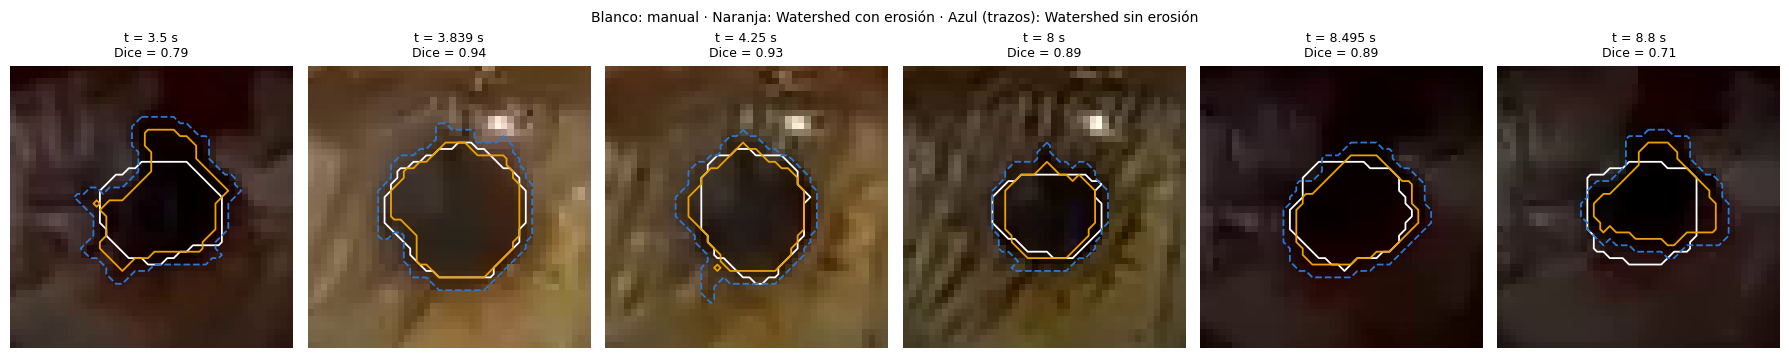

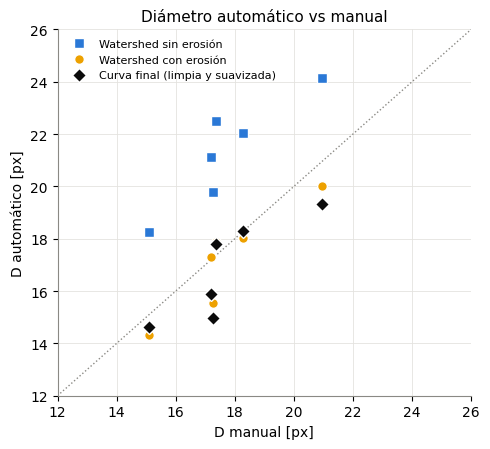

In [28]:
# Contornos manual / automático en cada frame anotado
# (solo si hay anotaciones manuales de este video)
if not hay_validacion:
    print("Sin anotaciones manuales de este video: no se grafica la validación.")
else:
    # Se genera la imagen con las 3 máscaras sobre cada ROI
    fig, ejes = plt.subplots(1, len(masks_val), figsize=(3 * len(masks_val), 3.5), squeeze=False)
    for ax, (t, m) in zip(ejes[0], masks_val.items()):
        ys, xs = np.nonzero(m["manual"])
        cy, cx, lado = int(ys.mean()), int(xs.mean()), 22
        sl = (slice(max(cy - lado, 0), cy + lado), slice(max(cx - lado, 0), cx + lado))
        ax.imshow(m["roi"][sl], interpolation="nearest")
        for mk, col, ls in [(m["manual"], COLOR["manual"], "-"), (m["watershed"], COLOR["watershed"], "--"),
                            (m["auto"], COLOR["auto"], "-")]:
            if mk is not None:
                ax.contour(mk[sl] > 0, levels=[0.5], colors=col, linewidths=1.3, linestyles=ls)
        f = tabla_val[tabla_val.t_s == t].iloc[0]
        ax.set_title(f"t = {t} s\nDice = {f.dice_auto:.2f}", fontsize=9)
        ax.axis("off")
    plt.suptitle("Blanco: manual · Naranja: Watershed con erosión · Azul (trazos): Watershed sin erosión",
                 y=1.02, fontsize=10)
    plt.tight_layout()
    fig.savefig(carpeta_res / "3_2_1_validacion_contornos.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Se genera la figura de dispersión de los diámetros manual vs automático
    fig, ax = plt.subplots(figsize=(5, 4.6))
    lim = [12, 26]
    ax.plot(lim, lim, color="#8a8984", lw=1, ls=":")
    for col, nombre, color, marca in [("D_watershed_px", "Watershed sin erosión", COLOR["watershed"], "s"),
                                      ("D_auto_px", "Watershed con erosión", COLOR["auto"], "o"),
                                      ("D_curva_suave_px", "Curva final (limpia y suavizada)", "#0b0b0b", "D")]:
        ok = tabla_val[col] < lim[1]
        ax.plot(tabla_val.D_manual_px[ok], tabla_val[col][ok], marca, color=color, mec="white", label=nombre)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("D manual [px]")
    ax.set_ylabel("D automático [px]")
    ax.set_title("Diámetro automático vs manual")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    plt.tight_layout()
    fig.savefig(carpeta_res / "3_2_1_validacion_dispersion.png", dpi=150, bbox_inches="tight")
    plt.show()

**Discusión (validación).**

* **Watershed sin morfología sobreestima siempre** el diámetro: sesgo de +7,1 px (MAE 7,1 px, RMSE 10,9 px), coherente con el área 1,4–1,8 veces mayor que se vio en 2.2.
* **Con la erosión** el error baja mucho en los frames bien segmentados: en los 3 frames con luz (3,839; 4,25 y 8 s) el error es menor a 0,5 px y el Dice va de 0,85 a 0,96. El MAE en los 6 frames (4,3 px; RMSE 8,5 px) lo domina **un solo frame fallido**, el de 8,495 s: es el primer frame después de apagar la luz, la cámara todavía no corrigió la exposición y la segmentación tomó casi todo el iris (D = 37,7 px, Dice 0,30). La diferencia entre MAE y RMSE refleja eso: el RMSE castiga mucho ese error grande.
* Si se evalúa **solo en los frames que la limpieza de artefactos acepta** (4 de 6), el MAE es de 1,2 px.
* **La curva final** (sin artefactos, interpolada y suavizada) tiene **MAE = 1,18 px y RMSE = 1,52 px** en diámetro (≈ 0,2 mm) y MAE = 31 px² en área, con un sesgo de −1,1 px: el frame fallido ya no pesa, porque se rechazó y se reemplazó por interpolación.

Los peores frames que quedan son los **oscuros** (3,5 y 8,8 s, Dice 0,66–0,78): con poca luz el **reflejo de la ventana sobre la córnea** tapa parte del borde de la pupila y la máscara automática queda irregular. Ese reflejo afecta también a la anotación manual: a 3,5 s se marcaron 17,4 px y a 3,839 s (el primer frame con luz, 0,34 s después y **antes** de que la pupila pueda empezar a contraerse) 21,0 px. La pupila no cambió en ese tiempo: lo que cambió es cuánto de ella se ve. **En oscuridad, tanto la medida manual como la automática subestiman el diámetro real.**

Limitaciones: son solo 6 frames, anotados por una sola persona y con píxeles enteros (un error de ±1 px en el borde son ±2 px en el diámetro).

## 3. Artefactos: fuentes, detección y tratamiento

**Fuentes de artefactos en este registro**

* **Parpadeos**: el párpado tapa el ojo; `seg.estimar_pupila` no encuentra un iris con contraste y devuelve None, o la máscara toma una forma alargada.
* **Movimientos oculares y de la cabeza**: la ROI es fija y el ojo se desplaza dentro de ella. Un movimiento lento no afecta la medida (la pupila sigue dentro de la ROI); uno brusco (sacada) desenfoca el frame.
* **Reflejo corneal de la ventana**: en oscuridad, la ventana se refleja en la córnea justo sobre la pupila y tapa parte de su borde (ver la anotación de t = 3,5 s). La máscara queda irregular y más chica de lo real.
* **Transición de iluminación y autoexposición**: al apagar la luz la imagen se oscurece de golpe y la cámara tarda varios frames en corregir la exposición; en esos frames la estimación del centro/radio puede agarrar otra estructura (el iris entero).
* **Compresión del video** (H.264, ver Módulo 4): suaviza el borde de una pupila de solo ~15–20 px.

**Método implementado** (`di.limpiar_senal`, parámetros en `modulo3.artefactos`). Cada frame se marca con el primer criterio que no cumple:

1. *Sin pupila*: estimar_pupila devolvió None (parpadeo).
2. *Forma*: circularidad < 0,55 o excentricidad > 0,90. La pupila es casi circular; una máscara muy irregular o alargada se "escapó" hacia un reflejo, una pestaña o el párpado.
3. *Salto del centroide*: el centroide se movió más de 8 px respecto del frame anterior (≈ 240 px/s): movimiento brusco o segmentación de otra estructura.
4. *Outlier (filtro de Hampel)*: en una ventana móvil de 1 s se calcula la mediana de D y su MAD; si |D − mediana| > 3·1,4826·MAD, el valor es atípico. Se usa la mediana y el MAD, y no la media y el desvío, porque los propios outliers no los arrastran.

Los frames rechazados pasan a NaN. Los **huecos de hasta 0,35 s** (~10 frames, más que un parpadeo típico de 0,1–0,3 s) se **interpolan linealmente** entre los valores válidos vecinos; los más largos quedan en NaN para no inventar señal. Finalmente la curva se **suaviza** con una mediana móvil de 5 frames (quita picos aislados sin redondear los cambios bruscos) y un filtro gaussiano de σ = 0,1 s (pasa-bajos: atenúa el ruido de alta frecuencia que la derivada amplificaría).

In [29]:
conteo = curva.motivo.replace("", "válido").value_counts().rename("frames").to_frame()
conteo["%"] = 100 * conteo.frames / len(curva)
display(conteo)
print(f"Frames interpolados: {int(curva.interpolado.sum())}  |  "
      f"sin dato (huecos largos): {int(curva.diametro_limpio_px.isna().sum())}")

,frames,%
motivo,,
válido,252,86.007
forma,38,12.969
outlier,3,1.024


Frames interpolados: 39  |  sin dato (huecos largos): 2


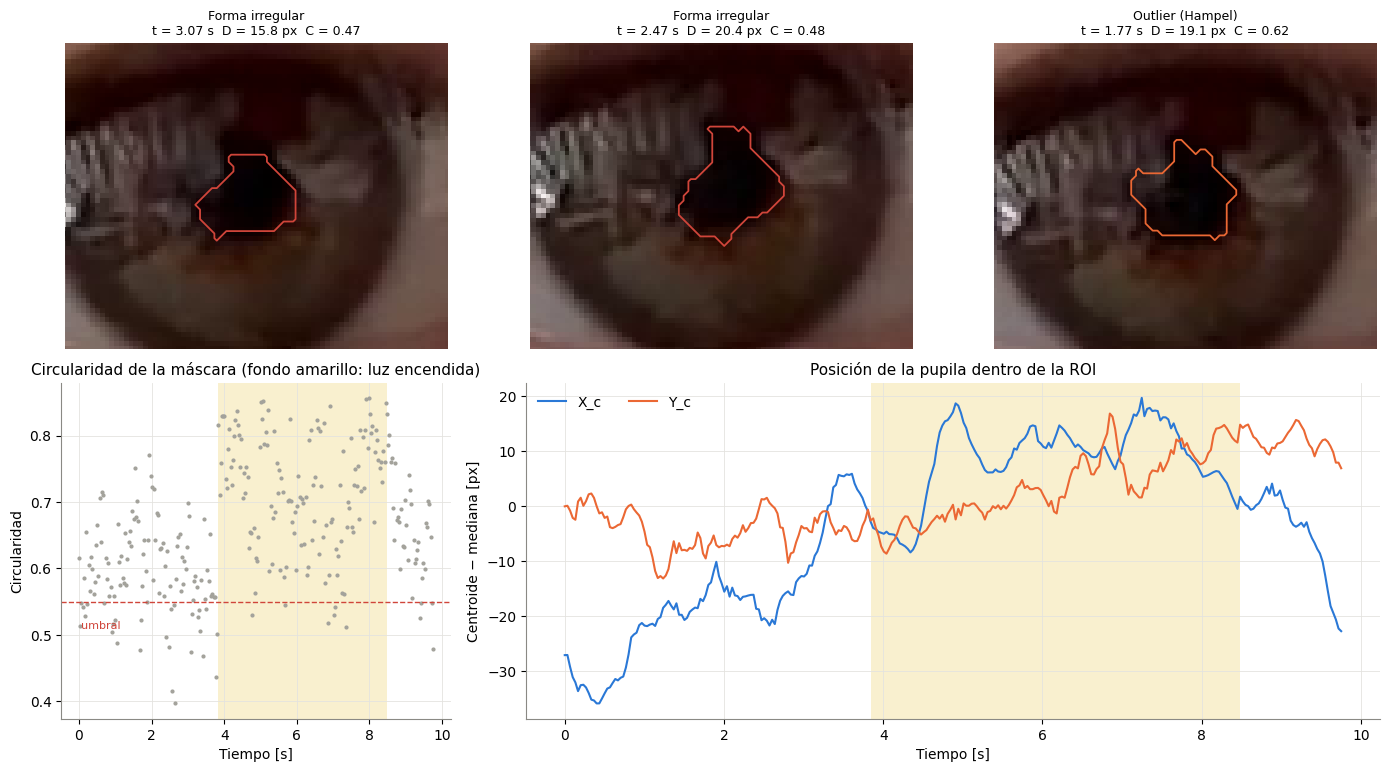

In [30]:
# Un ejemplo de cada tipo de artefacto + circularidad y posición del centroide en el tiempo
ejemplos = [curva[curva.motivo == m].iloc[len(curva[curva.motivo == m]) // 2]
            for m in ["forma", "salto_centroide", "outlier"] if (curva.motivo == m).any()]
ejemplos.insert(1, curva.loc[curva[curva.motivo == "forma"].diametro_px.idxmax()])   # la peor falla
ruta = str(ruta_video)

fig = plt.figure(figsize=(14, 7.8))
gs = fig.add_gridspec(2, len(ejemplos), height_ratios=[1, 1.1])
for k, f in enumerate(ejemplos):
    ax = fig.add_subplot(gs[0, k])
    roi_f = cm.recortar_roi(cm.extraer_frame(ruta, f.t_s), cfg["roi"])
    mk = de.mascara_pupila(roi_f, cfg)["mascara"]
    ax.imshow(roi_f, interpolation="nearest")
    if mk is not None:
        ax.contour(mk > 0, levels=[0.5], colors=COLOR_MOTIVO[f.motivo], linewidths=1.3)
    ax.set_xlim(f.cx - 40, f.cx + 40); ax.set_ylim(f.cy + 32, f.cy - 32)
    ax.set_title(f"{MOTIVO[f.motivo]}\nt = {f.t_s:.2f} s  D = {f.diametro_px:.1f} px  C = {f.circularidad:.2f}",
                 fontsize=9)
    ax.axis("off")

ax1 = fig.add_subplot(gs[1, :len(ejemplos) // 2])
ax2 = fig.add_subplot(gs[1, len(ejemplos) // 2:])
for ax in (ax1, ax2):
    sombrear_luz(ax, est, curva.t_s.iloc[-1])
ax1.plot(curva.t_s, curva.circularidad, ".", color=COLOR["crudo"], ms=4)
ax1.axhline(c3["artefactos"]["circularidad_min"], color=COLOR_MOTIVO["forma"], lw=1, ls="--")
ax1.text(0.05, c3["artefactos"]["circularidad_min"] - 0.04, "umbral", color=COLOR_MOTIVO["forma"], fontsize=8)
ax1.set_ylabel("Circularidad"); ax1.set_xlabel("Tiempo [s]")
ax1.set_title("Circularidad de la máscara (fondo amarillo: luz encendida)")
ax2.plot(curva.t_s, curva.cx - curva.cx.median(), color="#2a78d6", lw=1.5, label="X_c")
ax2.plot(curva.t_s, curva.cy - curva.cy.median(), color="#eb6834", lw=1.5, label="Y_c")
ax2.set_ylabel("Centroide − mediana [px]"); ax2.set_xlabel("Tiempo [s]")
ax2.set_title("Posición de la pupila dentro de la ROI")
ax2.legend(frameon=False, ncol=2)
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_2_artefactos.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (artefactos).** El 85,7 % de los frames (251 de 293) pasa todos los criterios. Se rechazaron 35 por forma (12 %), 5 como outliers de Hampel y 2 por salto del centroide; se interpolaron 41 frames y queda 1 sin dato (el último frame, que no tiene vecino posterior para interpolar). Ningún frame se rechazó por "sin pupila": en este video no hay parpadeos completos.

* **Reflejo corneal (el artefacto principal).** La circularidad es claramente **menor en oscuridad** (~0,6) que con luz (~0,73): el reflejo de la ventana tapa parte del borde y deja la máscara irregular (primer ejemplo, t = 3,31 s). Por eso casi todos los rechazos por forma están en los tramos oscuros. El reflejo **no se puede filtrar** frame a frame: no es un frame aislado malo sino un sesgo de todo el tramo oscuro (la pupila se ve más chica de lo que es). Se documenta y se tiene en cuenta al calcular los parámetros (sección 5).
* **Transición de iluminación.** Al apagar la luz (8,48–8,65 s) la imagen se oscurece de golpe y durante ~6 frames la segmentación toma casi todo el iris (D ≈ 34–39 px, segundo ejemplo). La forma irregular, el salto del centroide y el filtro de Hampel los detectan todos y el hueco (0,2 s) se interpola. Los dos frames rechazados por **salto del centroide** son justamente los que vuelven a la posición correcta después de la falla (tercer ejemplo): el criterio descarta de más un frame bueno, pero se recupera por interpolación.
* **Movimientos oculares y de la cabeza.** La posición de la pupila dentro de la ROI deriva lentamente unos 55 px en X a lo largo del video (movimiento de la cabeza o de la cámara al acercar la linterna), sin saltos bruscos. Como la ROI es fija pero holgada, la pupila nunca sale de ella y el movimiento lento no afecta la medida.
* **Outliers aislados.** 4 de los 5 outliers de Hampel son frames donde la máscara quedó más chica que sus vecinos (D ≈ 12–13 px contra ~14–15 px), por pestañas o compresión; el quinto (8,75 s) es una máscara demasiado grande justo después de la falla al apagar la luz.

Si en otro video hubiera **parpadeos**, se detectarían como "sin pupila" (párpado cerrado: no hay iris) o "forma" (párpado a medio cerrar: máscara alargada); un parpadeo dura 0,1–0,3 s, menos que el hueco máximo interpolable (0,35 s).

## 4. Curva temporal 1D: D(t) y A(t)

Arriba, el brillo medio del frame (con el que se detecta el estímulo, sección 5). En el medio, D(t): los puntos grises son la medida cruda de cada frame, las cruces los frames rechazados (con su motivo), la línea azul la curva limpia (con los huecos interpolados) y la negra la curva suavizada, que es la que se usa para los parámetros. Abajo, lo mismo para el área.

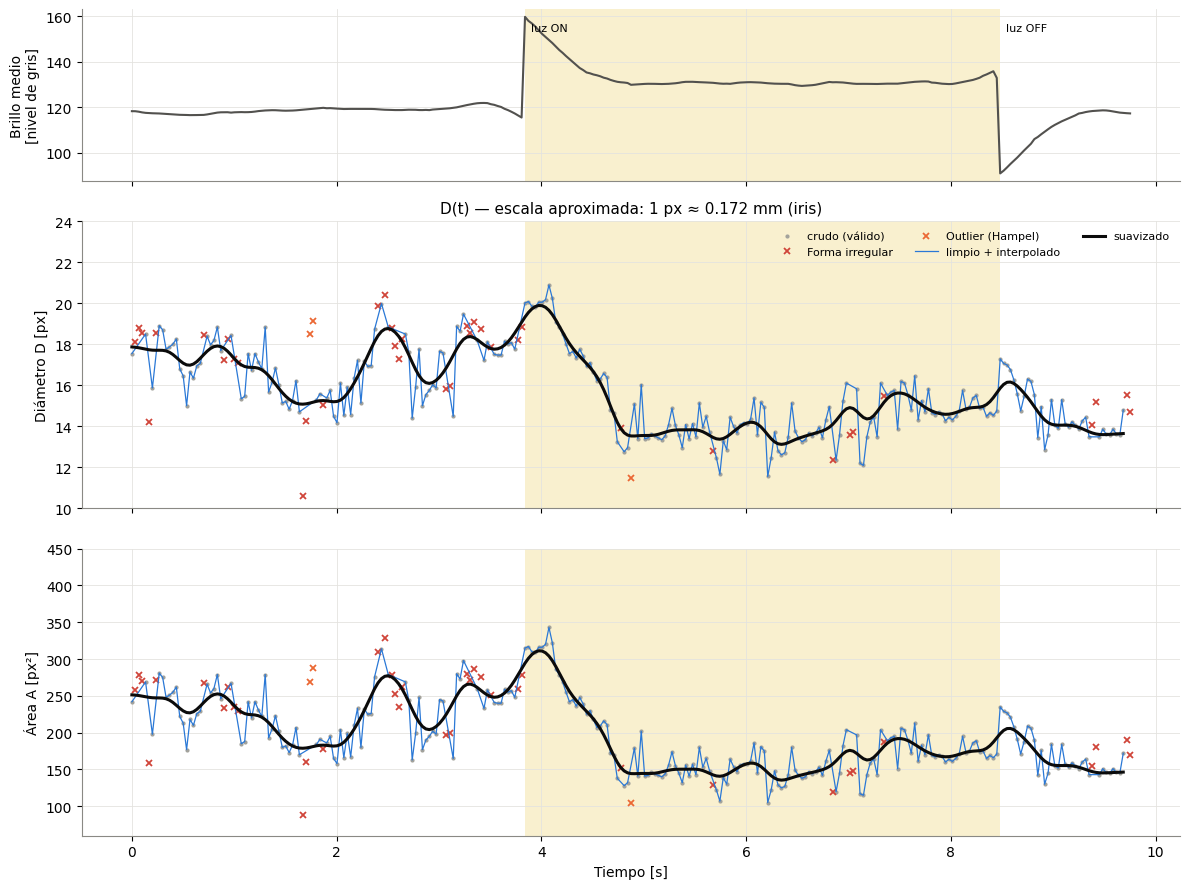

In [31]:
t_fin = curva.t_s.iloc[-1]
fig, ejes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [0.6, 1, 1]})

ax = ejes[0]
sombrear_luz(ax, est, t_fin)
ax.plot(curva.t_s, curva.brillo, color="#52514e", lw=1.5)
for t in est["encendido"]:
    ax.annotate("luz ON", (t, curva.brillo.max()), xytext=(4, -10), textcoords="offset points", fontsize=8)
for t in est["apagado"]:
    ax.annotate("luz OFF", (t, curva.brillo.max()), xytext=(4, -10), textcoords="offset points", fontsize=8)
ax.set_ylabel("Brillo medio\n[nivel de gris]")

for ax, cr, cl, cs, etiqueta, rango in [
        (ejes[1], "diametro_px", "diametro_limpio_px", "diametro_suave_px", "Diámetro D [px]", (10, 24)),
        (ejes[2], "area_px", "area_limpia_px", "area_suave_px", "Área A [px²]", (60, 450))]:
    sombrear_luz(ax, est, t_fin)
    ok = curva.valido
    ax.plot(curva.t_s[ok], curva[cr][ok], ".", color=COLOR["crudo"], ms=4, label="crudo (válido)")
    for m, col in COLOR_MOTIVO.items():
        sel = curva.motivo == m
        if sel.any():
            y = curva[cr][sel].clip(*rango)          # las fallas grandes se dibujan en el borde
            ax.plot(curva.t_s[sel], y, "x", color=col, ms=5, mew=1.3, label=MOTIVO[m])
    ax.plot(curva.t_s, curva[cl], color=COLOR["interp"], lw=0.9, label="limpio + interpolado")
    ax.plot(curva.t_s, curva[cs], color=COLOR["suave"], lw=2.2, label="suavizado")
    ax.set_ylim(*rango)
    ax.set_ylabel(etiqueta)
ejes[1].legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
ejes[2].set_xlabel("Tiempo [s]")
esc = resultado["mm_por_px"]
ejes[1].set_title(f"D(t) — escala aproximada: 1 px ≈ {esc:.3f} mm (iris)" if esc else "D(t)")
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_3_curva_temporal.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (curva temporal) para Video_Sofi_1.**:

1. **Oscuridad (0–3,8 s)**: D ≈ 15–18 px, con oscilaciones de ±1,5 px debidas sobre todo al reflejo de la ventana.
2. **Antes del estímulo (3,5–3,8 s)** D sube hasta ~18 px y sigue subiendo hasta 20,2 px a los 4,0 s. Esa subida empieza **antes** de encender la luz, y el brillo del frame **baja** un poco justo antes del salto (de 125 a 118): al acercar el celular con la linterna se sombrea la cara, el reflejo de la ventana se debilita y se ve más pupila. Es un artefacto de medición, no una dilatación.
3. **Constricción (4,0–5,1 s)**: D cae de 20,1 a 14,1 px (A de ~320 a ~155 px²) en poco más de 1 s.
4. **Luz sostenida (5,1–8,5 s)**: D ≈ 14–15,5 px, con oscilaciones lentas de ~1 px. Pueden ser en parte fisiológicas (la pupila nunca está quieta con luz constante: *hippus*), pero son del orden del ruido de la medida y no se analizan.
5. **Luz apagada (8,5–9,8 s)**: después de los frames fallidos, D **no aumenta** (15,6 → 13,7 px). La redilatación es lenta (segundos) y el video termina 1,3 s después de apagar la luz; además, al volver la oscuridad vuelve el reflejo de la ventana, que hace ver la pupila más chica. Este error se debe a que el video se cortó antes de que el reflejo se activara nuevamente.

A(t) tiene la misma forma que D(t) (A = π·D²/4), con cambios relativos aproximadamente el doble: la amplitud relativa en área es mayor que en diámetro.

## 5. Parámetros fisiológicos

### 5.1 Detección del estímulo

El estímulo se detecta solo, sin marcarlo a mano: al encender la linterna se ilumina toda la cara y el **brillo medio del frame** sube de golpe de un frame al siguiente; al apagarla, baja. La autoexposición de la cámara corrige después el brillo, pero lentamente (en varios frames). Por eso se busca un **salto** en Δb[n] = b[n] − b[n−1] mayor que un umbral = max(6 niveles, 10·1,4826·MAD(Δb)). El instante del estímulo es el del primer frame con la luz cambiada (resolución: 1 frame = 33 ms). Si un video no tuviera un salto claro, los tiempos se pueden fijar en `modulo3.estimulo`.

Umbral de salto de brillo: 6.0 niveles/frame
Luz encendida en t = [3.840529010238908] s  |  apagada en t = [8.482559726962458] s


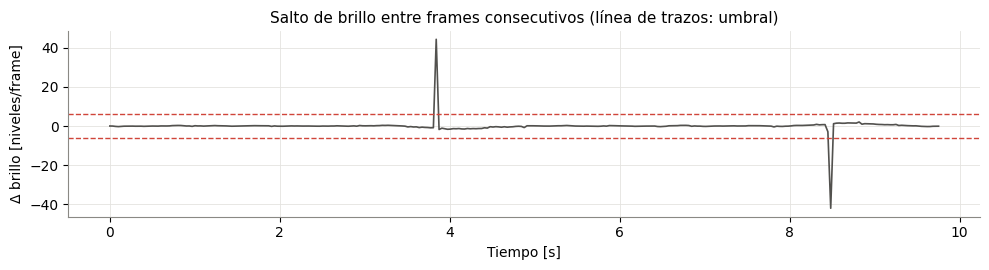

In [32]:
print(f"Umbral de salto de brillo: {est['umbral']:.1f} niveles/frame")
print(f"Luz encendida en t = {est['encendido']} s  |  apagada en t = {est['apagado']} s")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(curva.t_s, est["delta_brillo"], color="#52514e", lw=1.2)
for s in (1, -1):
    ax.axhline(s * est["umbral"], color="#d0453a", lw=1, ls="--")
ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("Δ brillo [niveles/frame]")
ax.set_title("Salto de brillo entre frames consecutivos (línea de trazos: umbral)")
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_4_estimulo.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Latencia, amplitud y velocidades

`di.extraer_parametros` analiza una **constricción** por cada encendido y una **redilatación** por cada apagado, sobre la curva suavizada:

* **Basal**: mediana de D (y de A) en el segundo previo al estímulo.
* **Velocidad** v = dD/dt (derivada numérica, `np.gradient`). Se busca el **pico de velocidad** en el sentido esperado (negativo en la constricción, positivo en la redilatación) en los 2 s siguientes al estímulo.
* **Inicio de la respuesta**: desde el pico de velocidad se retrocede mientras |v| sea mayor que el 20 % de |v_pico|. **Latencia** = t_inicio − t_estímulo. Se usa la velocidad y no un umbral sobre D porque la curva antes del estímulo tiene un sesgo (sección 6): un umbral de "D cae X % por debajo del basal" se cruzaría tarde.
* **Amplitud**: diferencia entre el basal y el extremo (mínimo en la constricción, máximo en la redilatación), en D, en A y en %. Se informa también la amplitud medida **desde el inicio** de la respuesta.
* **Velocidad media**: cambio de D entre el inicio y el extremo dividido por la duración.
* **Control de calidad**: la respuesta se considera detectada si su cambio supera 3 veces el ruido de la curva en el período basal (1,4826·MAD) y si el inicio o el pico no caen en un tramo interpolado. Si no, la latencia y las velocidades quedan en NaN.

**Escala.** Para dar los valores también en mm se usa el **iris como regla** porque su diámetro horizontal es casi constante entre adultos (≈ 11,7 mm) y está en el mismo plano que la pupila; mm/px = 11,7 / (2·mediana del radio del iris). Como control, en el Video_Sofi_1 hay una regla sobre la cara: el período de sus rayitas se mide con la **transformada de Fourier** del perfil de intensidad (como en el Módulo 1.3).

In [33]:
esc_iris = resultado["mm_por_px"]
reg = c3["escala"].get("regla")
if reg:
    esc_regla, f_regla, mag_regla = di.mm_por_px_regla(
        cm.extraer_frame(ruta_video, reg["tiempo_s"]), reg["fila_px"], reg["x0_px"], reg["x1_px"])
    print(f"Escala con el iris : {esc_iris:.4f} mm/px  ({1 / esc_iris:.2f} px/mm; radio del iris "
          f"mediano = {curva.radio_iris_px.median():.0f} px)")
    print(f"Escala con la regla: {esc_regla:.4f} mm/px  ({1 / esc_regla:.2f} px/mm)  "
          f"-> diferencia {100 * (esc_iris / esc_regla - 1):.0f} %")

cols = ["tipo", "respuesta_detectada", "t_estimulo_s", "t_inicio_s", "latencia_s", "t_extremo_s",
        "D_basal_px", "D_inicio_px", "D_extremo_px", "amplitud_D_px", "amplitud_D_pct",
        "amplitud_desde_inicio_D_px", "A_basal_px2", "A_extremo_px2", "amplitud_A_px2", "amplitud_A_pct",
        "v_pico_px_s", "v_media_px_s", "D_basal_mm", "D_extremo_mm", "amplitud_desde_inicio_D_mm",
        "v_pico_mm_s", "v_media_mm_s", "ruido_basal_px", "extremo_en_borde", "inicio_en_borde", "en_interpolado"]
display(par[[c for c in cols if c in par]].set_index("tipo").T)

Escala con el iris : 0.1721 mm/px  (5.81 px/mm; radio del iris mediano = 34 px)
Escala con la regla: 0.1531 mm/px  (6.53 px/mm)  -> diferencia 12 %


tipo,constriccion,redilatacion
respuesta_detectada,True,False
t_estimulo_s,3.841,8.483
t_inicio_s,4.041,NaN
latencia_s,0.2,NaN
t_extremo_s,5.744,8.583
D_basal_px,17.875,14.929
D_inicio_px,19.812,15.868
D_extremo_px,13.378,16.166
amplitud_D_px,4.498,1.237
amplitud_D_pct,25.161,8.286


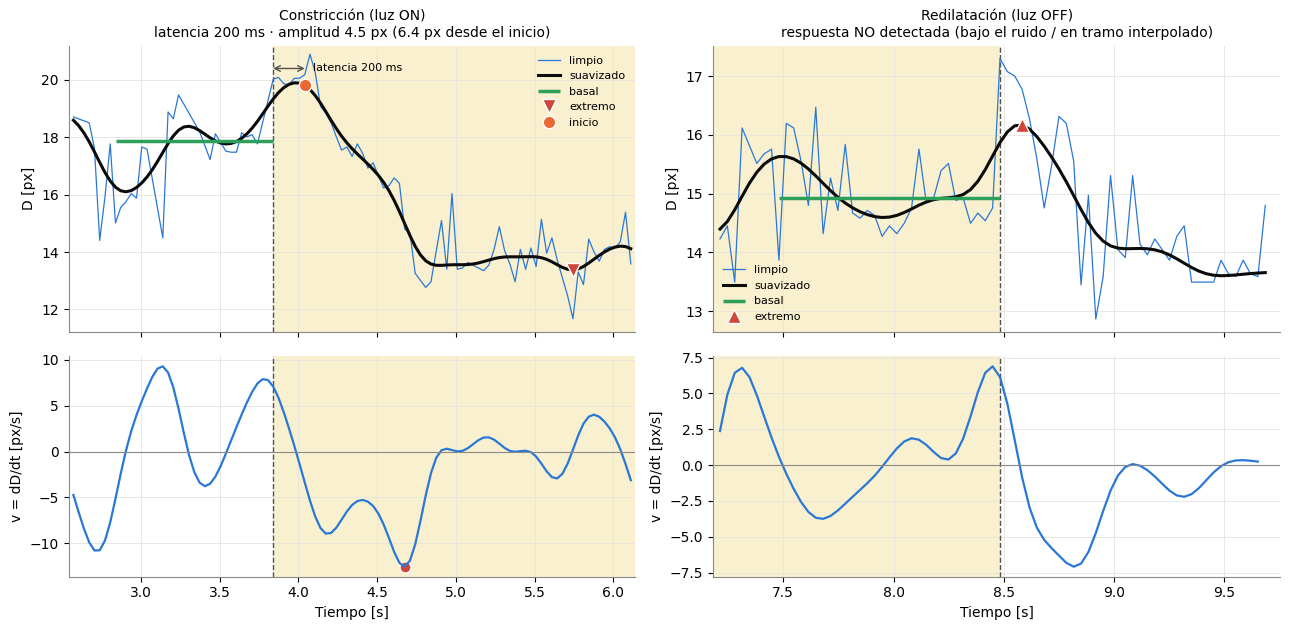

In [34]:
# Zoom sobre cada respuesta: D(t) con basal, inicio y extremo, y la velocidad
fig, ejes = plt.subplots(2, len(par), figsize=(6.5 * len(par), 6.4), sharex="col",
                         gridspec_kw={"height_ratios": [1.3, 1]}, squeeze=False)
for j, p in par.iterrows():
    t0 = p.t_estimulo_s - c3["parametros"]["ventana_basal_s"] - 0.3
    t1 = min(p.t_estimulo_s + c3["parametros"]["ventana_respuesta_s"] + 0.3, t_fin)
    tramo = curva[(curva.t_s >= t0) & (curva.t_s <= t1)]
    axd, axv = ejes[0, j], ejes[1, j]
    for ax in (axd, axv):
        sombrear_luz(ax, est, t_fin)
        ax.axvline(p.t_estimulo_s, color="#52514e", lw=1, ls="--")
    axd.plot(tramo.t_s, tramo.diametro_limpio_px, color=COLOR["interp"], lw=0.9, label="limpio")
    axd.plot(tramo.t_s, tramo.diametro_suave_px, color=COLOR["suave"], lw=2.2, label="suavizado")
    axd.hlines(p.D_basal_px, p.t_estimulo_s - c3["parametros"]["ventana_basal_s"], p.t_estimulo_s,
               color="#2e9e5b", lw=2.5, label="basal")
    axd.plot(p.t_extremo_s, p.D_extremo_px, "v" if p.tipo == "constriccion" else "^",
             color="#d0453a", mec="white", ms=10, label="extremo")
    titulo = "Constricción (luz ON)" if p.tipo == "constriccion" else "Redilatación (luz OFF)"
    if p.respuesta_detectada:
        axd.plot(p.t_inicio_s, p.D_inicio_px, "o", color="#eb6834", mec="white", ms=9, label="inicio")
        y_lat = tramo.diametro_suave_px.max() + 0.5
        axd.annotate("", xy=(p.t_inicio_s, y_lat), xytext=(p.t_estimulo_s, y_lat),
                     arrowprops=dict(arrowstyle="<->", color="#52514e", lw=1, shrinkA=0, shrinkB=0))
        axd.text(p.t_inicio_s + 0.05, y_lat, f"latencia {1000 * p.latencia_s:.0f} ms",
                 ha="left", va="center", fontsize=8)
        axd.set_ylim(top=y_lat + 0.8)
        axv.plot(p.t_v_pico_s, -p.v_pico_px_s if p.tipo == "constriccion" else p.v_pico_px_s,
                 "o", color="#d0453a", mec="white", ms=8)
        titulo += f"\nlatencia {1000 * p.latencia_s:.0f} ms · amplitud {p.amplitud_D_px:.1f} px " \
                  f"({p.amplitud_desde_inicio_D_px:.1f} px desde el inicio)"
    else:
        titulo += "\nrespuesta NO detectada (bajo el ruido / en tramo interpolado)"
    axd.set_title(titulo, fontsize=10)
    axd.set_ylabel("D [px]")
    axd.legend(frameon=False, fontsize=8, loc="upper right" if p.tipo == "constriccion" else "lower left")
    axd.set_xlim(t0, t1)
    axv.plot(tramo.t_s, tramo.velocidad_px_s, color="#2a78d6", lw=1.6)
    axv.axhline(0, color="#8a8984", lw=0.8)
    axv.set_ylabel("v = dD/dt [px/s]")
    axv.set_xlabel("Tiempo [s]")
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_5_parametros.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (parámetros).**

* **Estímulo**: los saltos de brillo (+44 niveles de gris al encender y −42 al apagar) superan por mucho el umbral de 6 niveles/frame, así que la detección es inequívoca: luz ON a 3,84 s y OFF a 8,48 s.
* **Latencia de constricción: 200 ms** (inicio de la caída a 4,04 s). Está dentro del rango habitual del reflejo fotomotor en adultos (≈ 0,2–0,3 s). La resolución es de un frame (33 ms) y el suavizado (σ = 0,1 s) puede adelantar un poco el inicio aparente.
* **Amplitud**: la constricción lleva D de **20,1 px a 14,1 px**: **6,0 px desde el inicio (30 %; ≈ 1,0 mm)**. Medida desde el basal de oscuridad, como pide la consigna, da 3,2 px (18,6 %) en diámetro y 81 px² (34 %) en área. La diferencia entre las dos se debe al sesgo del basal: en oscuridad el reflejo tapa parte de la pupila y el basal de 17,4 px es menor que la pupila real. Por eso conviene informar la amplitud desde el inicio de la respuesta, o mejorar la iluminación del registro para que no se refleje la ventana.
* **Velocidad de constricción**: pico de **9,8 px/s (≈ 1,7 mm/s)**, media de 5,4 px/s (≈ 0,9 mm/s) en 1,1 s de constricción. El suavizado atenúa los cambios rápidos, así que el pico es una cota inferior. Además, antes del estímulo la velocidad oscila hasta ±9 px/s por el ruido del reflejo: la velocidad pico de la constricción apenas sobresale del ruido de la oscuridad. Por eso la latencia se buscó **solo después del estímulo** y retrocediendo desde el pico.
* **Redilatación: no detectada.** Su cambio (0,6 px) no supera 3 veces el ruido basal y el pico de velocidad cae en el tramo interpolado de la transición de luz. La latencia y la velocidad de redilatación quedan en NaN: con este video no se pueden medir.
* **Escala**: con el iris (radio mediano 34 px) 1 px ≈ 0,172 mm; con la regla, medida por Fourier, 0,153 mm/px. La diferencia de 12 % se explica porque la regla está apoyada en la mejilla, más cerca de la cámara que el ojo (se ve más grande), porque 11,7 mm es un promedio poblacional (±0,5 mm) y porque el radio del iris se estima en pasos de 2 px. Los valores en mm son aproximados (±10–15 %).

## 6. Variabilidad entre trials / registros

Cada encendido de la luz es un trial de constricción y cada apagado uno de redilatación. La variabilidad se calcula sobre **todos los trials con respuesta detectada** de todos los registros: el video de `entrada.video_path` y los que se agreguen en `modulo3.registros_extra` (cada uno con su video y su ROI). La tabla da n, media, desvío y coeficiente de variación (CV = desvío/media) de la latencia, la amplitud y la velocidad pico.

In [35]:
registros = {Path(cfg["entrada"]["video_path"]).stem: resultado}
for extra in c3.get("registros_extra") or []:
    nombre = Path(extra["video_path"]).stem
    print(f"Procesando {nombre}...")
    registros[nombre] = di.procesar_registro(raiz / extra["video_path"], cfg, roi=extra.get("roi"), verbose=False)

todos = pd.concat([r["parametros"].assign(registro=n) for n, r in registros.items()], ignore_index=True)
display(todos[["registro", "tipo", "respuesta_detectada", "latencia_s", "amplitud_D_px",
               "amplitud_A_px2", "v_pico_px_s"]])
var = di.variabilidad(todos)
var.to_csv(carpeta_res / "3_2_variabilidad.csv")
display(var)

,registro,tipo,respuesta_detectada,latencia_s,amplitud_D_px,amplitud_A_px2,v_pico_px_s
0,Video_Sofi_1,constriccion,True,0.2,4.498,110.350,12.544
1,Video_Sofi_1,redilatacion,False,NaN,1.237,30.631,NaN


n    media  desvio  cv_pct
tipo         parametro                                 
constriccion latencia_s      1    0.200     NaN     NaN
             amplitud_D_px   1    4.498     NaN     NaN
             amplitud_D_pct  1   25.161     NaN     NaN
             amplitud_A_px2  1  110.350     NaN     NaN
             v_pico_px_s     1   12.544     NaN     NaN

**Discusión (variabilidad).** Con este registro hay **un solo trial de constricción** detectado (y ningún trial de redilatación medible), así que la variabilidad **no se puede estimar**: el desvío y el CV quedan en NaN con n = 1. El código ya está preparado: alcanza con agregar los demás registros del Módulo 0 (2–3 de tipo A y 2–3 de tipo B) en `modulo3.registros_extra` para obtener media ± desvío y CV de la latencia, la amplitud y la velocidad.

Se probó el otro video disponible en `data/videos` (Video_Delca_1, con una ROI propia), pero en ese registro el reflejo de la pantalla del celular cubre la pupila en la mayoría de los frames (116 de 213 se rechazan por forma) y no se detecta ninguna respuesta. Por eso no se incluyó. Para obtener la variabilidad hacen falta registros con el ojo más cerca de la cámara (pupila de más píxeles) y sin una fuente de luz que se refleje sobre la pupila.

## 7. Salida estandarizada (CSV)

`di.exportar_csv` guarda, para cada registro, dos archivos con columnas fijas en `results/modulo3/`:

* `<registro>_curva.csv`: una fila por frame — tiempo, brillo, si es válido y el motivo de rechazo, área y diámetro crudos, limpios y suavizados, velocidad, centroide y forma (y las columnas en mm si hay escala).
* `<registro>_parametros.csv`: una fila por respuesta — tipo, estímulo, latencia, basal, extremo, amplitudes (D, A, %), velocidades pico y media, y las banderas de calidad.

Para procesar otro video alcanza con cambiar `entrada.video_path` (y la `roi`) en `config.yaml` y ejecutar este notebook.

In [36]:
for nombre, r in registros.items():
    for ruta in di.exportar_csv(r, nombre, carpeta_res):
        print("Guardado:", ruta.relative_to(raiz))

Guardado: results\modulo3\Video_Sofi_1_curva.csv
Guardado: results\modulo3\Video_Sofi_1_parametros.csv


## 8. Conclusiones

1. **Automatización**: el pipeline Módulo 2 (CLAHE + Watershed) + erosión k = 3 × 2 procesa los 293 frames en ~40 s, sin intervención, y produce D(t) y A(t) en px y en mm (escala por el iris).
2. **Validación**: la curva final tiene **MAE = 1,18 px y RMSE = 1,52 px** en diámetro frente a la anotación manual (6 frames). La erosión elegida en 2.2 elimina el sesgo de +7 px de Watershed; el error que queda se concentra en los frames oscuros, donde el reflejo de la ventana tapa la pupila (y engaña también a la anotación manual).
3. **Artefactos**: el 86 % de los frames es válido. Se detectan con criterios de forma (circularidad, excentricidad), salto del centroide y filtro de Hampel; los huecos de hasta 0,35 s se interpolan linealmente y la curva se suaviza (mediana + gaussiano) antes de derivar. La falla grave del video (6 frames al apagar la luz, D ≈ 35–39 px) queda totalmente filtrada.
4. **Parámetros**: el estímulo se detecta automáticamente por el salto de brillo del frame. Constricción con **latencia de 200 ms**, amplitud de **6,0 px (30 %, ≈ 1,0 mm)** desde el inicio de la respuesta (3,2 px / 18,6 % desde el basal oscuro, que está sesgado hacia abajo), velocidad pico de **9,8 px/s (≈ 1,7 mm/s)** y media de 5,4 px/s. La redilatación no se puede medir: el video termina 1,3 s después de apagar la luz.
5. **Variabilidad**: con un solo trial no se puede estimar; el código ya la calcula cuando se agregan más registros.

**Limitaciones y mejoras**: la fuente de error dominante es el reflejo de la ventana en oscuridad, que sesga el basal; se resolvería en la adquisición (cuarto oscuro, sin fuentes de luz frente al ojo) más que en el procesamiento. La pupila mide solo 14–20 px: grabar más cerca o con más resolución reduciría el error relativo. Para medir la redilatación hacen falta varios segundos de registro después de apagar la luz, como pide el protocolo del Módulo 0.